# 03 — Perceptron ve LightGBM

**Sahibi:** Öğrenci 2 · **Rubrik:** Model Engineering — Perceptron ve GBDT (20 puanın parçası)

| Bölüm | İçerik | Çıktı |
|---|---|---|
| 1 | Veri | — |
| 2 | Referans çizgisi: DummyClassifier | — |
| 3 | Perceptron: parametre taraması | `reports/perceptron_sweep.csv` |
| 4 | Perceptron: öğrenme eğrisi | `figures/extra_perceptron_curve.png` |
| 5 | LightGBM: varsayılan model ve CV | — |
| 6 | LightGBM: Optuna araması | `models/optuna_lgbm.db` |
| 7 | Optuna grafikleri, özellik önemi | `figures/extra_optuna_*.png`, `models/importance/lgbm_importance.csv` |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
import time
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier, early_stopping
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline

from src.config import (
    CAT_COLS, CAT_LEVELS, IMPORTANCE_DIR, MODELS_DIR, NOMINAL_COLS, REPORTS_DIR, SEED,
)
from src.data import load_split, to_xy
from src.features import make_preprocessor
from src.metrics import evaluate, pick_threshold
from src.plots import INK_MUTED, SERIES, save_fig, set_style

# Single switch for the training data: "clean", "smote" or "ctgan" (val/test are always clean)
VARIANT = "clean"

set_style()
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Veri

Öğrenci 1'in temizlenmiş ve doldurulmuş verisi (`clean`). Model seçimi **val** setinde
yapılır; **test** seti en sona, final modellere ayrılmıştır ve bu bölümde yüklenmez.

In [3]:
train = load_split("train", VARIANT)
val = load_split("val", "clean")
X_train, y_train = to_xy(train)
X_val, y_val = to_xy(val)

pd.DataFrame(
    {
        "rows": [len(train), len(val)],
        "default_rate": [y_train.mean(), y_val.mean()],
    },
    index=[f"train ({VARIANT})", "val"],
)

,rows,default_rate
train (clean),20975,0.2213
val,4495,0.2211


## 2. Referans çizgisi: DummyClassifier

`DummyClassifier` özelliklere hiç bakmaz. Gerçek modellerin skorları ancak bu referansla
kıyaslanınca anlam kazanır.

- **most_frequent:** herkese çoğunluk sınıfını (0 = ödeyecek) söyler.
- **stratified:** sınıf oranına göre rastgele tahmin eder (%22 olasılıkla 1).

In [4]:
results = {}
for strategy in ("most_frequent", "stratified"):
    dummy = DummyClassifier(strategy=strategy, random_state=SEED).fit(X_train, y_train)
    # Dummy models have no meaningful score to tune a threshold on, so predict() is used as is
    y_score = dummy.predict_proba(X_val)[:, 1]
    results[f"dummy_{strategy}"] = evaluate(y_val, y_score, dummy.predict(X_val))

pd.DataFrame(results).T

,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy
dummy_most_frequent,0.4378,0.6820,0.5000,0.2211,0.7789
dummy_stratified,0.5019,0.6573,0.5019,0.2218,0.6578


**Yorum**

- **Accuracy tuzağı:** `most_frequent` tek bir temerrüdü bile yakalamadan **%77,9 accuracy**
  alıyor. Macro-F1 ise 0,438: sınıf 0'ın F1'i ≈ 0,876, sınıf 1'in F1'i 0, ortalaması 0,438.
  Accuracy bu yüzden yalnızca bilgi amaçlı raporlanıyor.
- **Eşikten bağımsız metriklerin tabanı:** rastgele skorlarda ROC-AUC ≈ 0,50 ve PR-AUC ≈ val'deki
  pozitif oranı (0,221). PR eğrisinin taban çizgisi bu yüzden 0,22.
- **`stratified`** sınıf oranında rastgele tahminle macro-F1 ≈ 0,50 alıyor; accuracy'si ise
  çoğunluk tahmininden *düşük* (0,658). Accuracy'ye bakan biri yanlış modeli seçerdi.
- **Hedef:** Gerçek modellerin macro-F1'de 0,50'nin, PR-AUC'de 0,22'nin belirgin üstüne çıkması
  gerekiyor. Öğrenci 1'in sabit parametreli LightGBM'i val'de 0,707 / 0,550 almıştı
  (`reports/tstr_trtr.csv`), iyi bir sonucun ölçeği bu.

## 3. Perceptron

Perceptron skoru $s = w \cdot x + b$ hesaplar ve $s > 0$ ise 1 der. Yalnızca **yanlış
sınıflandırdığı** satırda ağırlıkları günceller: $w \leftarrow w + \eta_0 \, y \, x$
($y \in \{-1, +1\}$).

- **Ön işleme:** `make_preprocessor("linear")` — nominal kolonlara one-hot, geri kalanına
  RobustScaler. Pipeline içinde olduğu için ölçekleyici **yalnızca train'e** fit edilir;
  val'e train'in medyan/IQR değerleriyle uygulanır.
- **Skor ve eşik:** Perceptron olasılık vermez; ham skor `decision_function` kullanılır.
  Eşik val'de `pick_threshold` ile macro-F1'i maksimize edecek şekilde seçilir.
- **Tarama:** `eta0` × `penalty` × `alpha` × `class_weight`. `penalty=None` iken `alpha`
  kullanılmadığı için o kombinasyonlar tek kez eğitilir (50 konfigürasyon).
- **5 tohum:** Veri doğrusal ayrılamadığı için Perceptron'un ağırlıkları salınır ve sonuç
  satırların karıştırılma sırasına (`random_state`) çok duyarlıdır. Tek tohumla seçim yapmak
  şanslı bir sırayı seçmek olur. Bu yüzden her konfigürasyon 5 tohumla eğitilir, seçim
  **ortalama** macro-F1'e göre yapılır, standart sapma da raporlanır.

In [5]:
ETA0S = [1e-4, 1e-3, 1e-2, 0.1, 1.0]
PENALTIES = [None, "l2", "elasticnet"]
ALPHAS = [1e-4, 1e-3]
CLASS_WEIGHTS = [None, "balanced"]
SEEDS = [SEED + i for i in range(5)]
METRICS = ["macro_f1", "weighted_f1", "roc_auc", "pr_auc", "accuracy"]


def make_perceptron(seed: int = SEED, **params) -> Pipeline:
    params = {"max_iter": 1000} | params
    return make_pipeline(make_preprocessor("linear"), Perceptron(random_state=seed, **params))


def score_on_val(model: Pipeline) -> dict:
    """Val metrics at the macro-F1-optimal threshold, which is picked on val itself."""
    y_score = model.decision_function(X_val)
    threshold = pick_threshold(y_val, y_score)
    return evaluate(y_val, y_score, (y_score >= threshold).astype(int))


rows = []
start = time.perf_counter()
for eta0, penalty, alpha, class_weight in product(ETA0S, PENALTIES, ALPHAS, CLASS_WEIGHTS):
    if penalty is None and alpha != ALPHAS[0]:
        continue  # alpha only scales the penalty term
    params = {"eta0": eta0, "penalty": penalty, "alpha": alpha, "class_weight": class_weight}
    for seed in SEEDS:
        model = make_perceptron(seed, **params).fit(X_train, y_train)
        rows.append(params | {"seed": seed, "n_iter": model[-1].n_iter_} | score_on_val(model))
print(f"{len(rows)} model, {time.perf_counter() - start:.1f} sn")

runs = pd.DataFrame(rows)
# None would be dropped by groupby/pivot and lost in the CSV
runs[["penalty", "class_weight"]] = runs[["penalty", "class_weight"]].fillna("none")
stats = runs.groupby(["eta0", "penalty", "alpha", "class_weight"])[METRICS + ["n_iter"]]
sweep = stats.mean().join(stats.std()[["macro_f1", "pr_auc"]], rsuffix="_std").reset_index()
REPORTS_DIR.mkdir(exist_ok=True)
sweep.to_csv(REPORTS_DIR / "perceptron_sweep.csv", index=False)
cols = ["eta0", "penalty", "alpha", "class_weight"]
cols += ["macro_f1", "macro_f1_std", "pr_auc", "pr_auc_std"]
sweep.sort_values("macro_f1", ascending=False)[cols].head(10)

250 model, 79.0 sn


,eta0,penalty,alpha,class_weight,macro_f1,macro_f1_std,pr_auc,pr_auc_std
17,0.0010,l2,0.0010,none,0.6356,0.0303,0.4069,0.0680
22,0.0100,elasticnet,0.0010,balanced,0.6312,0.0324,0.3853,0.0504
25,0.0100,l2,0.0001,none,0.6281,0.0184,0.4032,0.0336
32,0.1000,elasticnet,0.0010,balanced,0.6236,0.0656,0.3806,0.0801
19,0.0010,none,0.0001,none,0.6235,0.0350,0.3798,0.0644
43,1.0000,elasticnet,0.0010,none,0.6211,0.0403,0.3884,0.0620
9,0.0001,none,0.0001,none,0.6197,0.0319,0.3673,0.0673
15,0.0010,l2,0.0001,none,0.6178,0.0253,0.3762,0.0618
37,0.1000,l2,0.0010,none,0.6147,0.0068,0.3663,0.0253
45,1.0000,l2,0.0001,none,0.6147,0.0068,0.3663,0.0253


### 3.1 `eta0` neden tek başına etkisiz?

sklearn ağırlıkları $w = 0$ ile başlatır. Her güncelleme $\eta_0$ ile çarpıldığı için eğitim
sonunda $w = \eta_0 \sum y_i x_i$ olur: $\eta_0$ yalnızca **ölçekler**. Skorun işareti, yani
karar sınırı değişmez. Ceza terimi eklenince her adımda ağırlıklar
$(1 - \eta_0 \alpha)$ ile küçültülür; bu çarpan $\eta_0$'a bağlı olduğu için artık sonuç
gerçekten değişir. Etkili büyüklük $\eta_0 \alpha$ çarpımıdır.

Aşağıdaki tabloda (5 tohum ortalaması, `alpha=1e-4`, `class_weight=None`) `none` satırı da
hafifçe oynuyor. Bunun sebebi teori değil, sklearn'ün **erken durma** kriteri: `tol` mutlak bir
eşik, kayıp ise $\eta_0$ ile ölçeklenir. Küçük $\eta_0$'da iyileşme `tol`'un altında kalır ve
eğitim daha erken durur; farklı epoch'ta durmak farklı ağırlık demektir.

In [6]:
subset = sweep[(sweep.alpha == ALPHAS[0]) & (sweep.class_weight == "none")]
subset.pivot(index="penalty", columns="eta0", values="macro_f1")

eta0,0.0001,0.0010,0.0100,0.1000,1.0000
penalty,,,,,
elasticnet,0.6124,0.5968,0.5650,0.5947,0.6068
l2,0.6107,0.6178,0.6281,0.5853,0.6147
none,0.6197,0.6235,0.6047,0.6047,0.6047


In [7]:
# Stopping epoch per seed for penalty=None: small eta0 stops earlier because tol is absolute
no_penalty = runs[(runs.penalty == "none") & (runs.class_weight == "none")]
no_penalty.pivot(index="seed", columns="eta0", values="n_iter")

eta0,0.0001,0.0010,0.0100,0.1000,1.0000
seed,,,,,
42,6,6,6,6,6
43,6,7,7,7,7
44,6,6,8,8,8
45,6,6,15,15,15
46,6,7,13,13,13


In [8]:
# With a fixed number of epochs (tol=None) the weights divided by eta0 match for every seed
FIXED_EPOCHS = 20
same_direction = []
for seed in SEEDS:
    coefs = [
        make_perceptron(seed, eta0=eta0, tol=None, max_iter=FIXED_EPOCHS)
        .fit(X_train, y_train)[-1]
        .coef_.ravel()
        / eta0
        for eta0 in ETA0S
    ]
    same_direction.append(all(np.allclose(coefs[0], c) for c in coefs))
print(f"Sabit {FIXED_EPOCHS} epoch, w / eta0 tüm eta0 değerlerinde aynı:")
print(dict(zip(SEEDS, same_direction)))

Sabit 20 epoch, w / eta0 tüm eta0 değerlerinde aynı:
{42: True, 43: True, 44: True, 45: True, 46: True}


### 3.2 Diğer parametrelerin etkisi

In [9]:
sweep.groupby(["penalty", "class_weight"])[["macro_f1", "pr_auc"]].max().unstack("class_weight")

macro_f1          pr_auc       
class_weight balanced   none balanced   none
penalty                                     
elasticnet     0.6312 0.6211   0.3853 0.3884
l2             0.6111 0.6356   0.3450 0.4069
none           0.6046 0.6235   0.3317 0.3798

### 3.3 Seçilen Perceptron

In [10]:
best = sweep.loc[sweep.macro_f1.idxmax()]
PERCEPTRON_PARAMS = {
    "eta0": float(best.eta0),
    "penalty": None if best.penalty == "none" else best.penalty,
    "alpha": float(best.alpha),
    "class_weight": None if best.class_weight == "none" else best.class_weight,
}
print("Seçilen parametreler:", PERCEPTRON_PARAMS)
print(f"macro-F1 = {best.macro_f1:.4f} ± {best.macro_f1_std:.4f} (5 tohum)")

results["perceptron (5 tohum ort.)"] = best[METRICS]
pd.DataFrame(results).T.astype(float)

Seçilen parametreler: {'eta0': 0.001, 'penalty': 'l2', 'alpha': 0.001, 'class_weight': None}
macro-F1 = 0.6356 ± 0.0303 (5 tohum)


,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy
dummy_most_frequent,0.4378,0.6820,0.5000,0.2211,0.7789
dummy_stratified,0.5019,0.6573,0.5019,0.2218,0.6578
perceptron (5 tohum ort.),0.6356,0.7560,0.6764,0.4069,0.7635


**Yorum**

- **Seçilen model:** `penalty="l2"`, `eta0=1e-3`, `alpha=1e-3`, `class_weight=None`.
  Val'de macro-F1 **0,636 ± 0,030**, PR-AUC 0,407 ± 0,068 (5 tohum). Referans çizgisinin
  (0,502 / 0,222) belirgin üstünde.
- **İlk 10 konfigürasyon birbirinden ayırt edilemiyor:** ortalamalar 0,615–0,636 arasında,
  standart sapmalar ise 0,02–0,07. Farklar tohum gürültüsünden küçük; yani Perceptron'un
  tavanı parametreden çok modelin kendisiyle sınırlı. Tek tohumla yapılan ilk taramada
  "kazanan" çıkan konfigürasyonun (`elasticnet`, `eta0=1`) 5 tohum ortalaması 0,621'de kaldı.
- **`class_weight="balanced"` tutarlı bir kazanç sağlamıyor.** Eşik zaten val'de macro-F1'e
  göre seçildiği için dengesizlik eşikle telafi ediliyor; sınıf ağırlığı ek bilgi getirmiyor.
  Öğrenci 1'in SMOTE için bulduğu sonuçla aynı.
- **Doğrusal modelin sınırı:** ROC-AUC 0,676. Öğrenci 1'in sabit parametreli LightGBM'i
  aynı val setinde 0,777 almıştı. Aradaki fark, özellikler ile temerrüt arasındaki doğrusal
  olmayan ilişkilerden (ör. PAY_x kodlarının etkisi) geliyor; LightGBM bölümünde bu farkı
  ölçeceğiz.
- Final modelde aynı parametreler `random_state=SEED` ile eğitilecek.

## 4. Perceptron öğrenme eğrisi

Seçilen Perceptron tur tur (epoch) eğitilir; her turdan sonra train ve val'de macro-F1 ve
Perceptron kaybı ölçülür. Kayıp yalnızca yanlış taraftaki satırları cezalandırır:
$\frac{1}{n}\sum \max(0, -y_i s_i)$, $y_i \in \{-1, +1\}$.

- `partial_fit` veriyi **bir kez** dolaşır; döngüde çağrılınca her turdan sonra ölçüm
  yapılabilir. Pipeline `partial_fit` desteklemediği için ön işleyici train'e ayrıca fit
  edilir ve veriler bir kez dönüştürülür.
- **Tuzak:** `random_state` bir *sayı* olursa sklearn her `partial_fit` çağrısında üreteci
  aynı tohumla yeniden kurar ve her tur **aynı karıştırma sırası** kullanılır (`fit` ise her
  tur farklı sıra kullanır). Bu yüzden `np.random.RandomState(seed)` nesnesi verilir;
  nesne çağrılar arasında ilerler ve her tur yeni bir sıra gelir.
- 5 tohum: val eğrisinin ortalaması ve en kötü–en iyi aralığı gösterilir.

In [11]:
N_EPOCHS = 50

preprocessor = make_preprocessor("linear").fit(X_train)
A_train = preprocessor.transform(X_train).to_numpy()
A_val = preprocessor.transform(X_val).to_numpy()


def perceptron_loss(y: pd.Series, y_score: np.ndarray) -> float:
    signed_y = 2 * np.asarray(y) - 1
    return float(np.maximum(0, -signed_y * y_score).mean())


def tuned_macro_f1(y: pd.Series, y_score: np.ndarray) -> float:
    threshold = pick_threshold(y, y_score)
    return evaluate(y, y_score, (y_score >= threshold).astype(int))["macro_f1"]


rows = []
start = time.perf_counter()
for seed in SEEDS:
    # A RandomState object advances between calls, so each epoch gets a new shuffle order
    model = Perceptron(random_state=np.random.RandomState(seed), **PERCEPTRON_PARAMS)
    for epoch in range(1, N_EPOCHS + 1):
        model.partial_fit(A_train, y_train, classes=np.array([0, 1]))
        for split, A, y in (("train", A_train, y_train), ("val", A_val, y_val)):
            y_score = model.decision_function(A)
            rows.append({
                "seed": seed, "epoch": epoch, "split": split,
                "macro_f1": tuned_macro_f1(y, y_score), "loss": perceptron_loss(y, y_score),
            })
print(f"{len(SEEDS)} tohum × {N_EPOCHS} tur, {time.perf_counter() - start:.1f} sn")

curves = pd.DataFrame(rows)
summary = curves.groupby(["split", "epoch"])[["macro_f1", "loss"]].agg(["mean", "min", "max"])
summary.loc["val"].iloc[[0, 1, 4, 9, 19, 49]]

5 tohum × 50 tur, 142.7 sn


macro_f1                 loss              
          mean    min    max   mean    min    max
epoch                                            
1       0.6013 0.5861 0.6238 0.0178 0.0053 0.0313
2       0.6022 0.5216 0.6597 0.0112 0.0062 0.0182
5       0.5772 0.4665 0.6223 0.0191 0.0057 0.0531
10      0.5761 0.5425 0.6147 0.0184 0.0114 0.0248
20      0.5839 0.5507 0.6170 0.0186 0.0074 0.0300
50      0.5832 0.4918 0.6403 0.0142 0.0076 0.0284

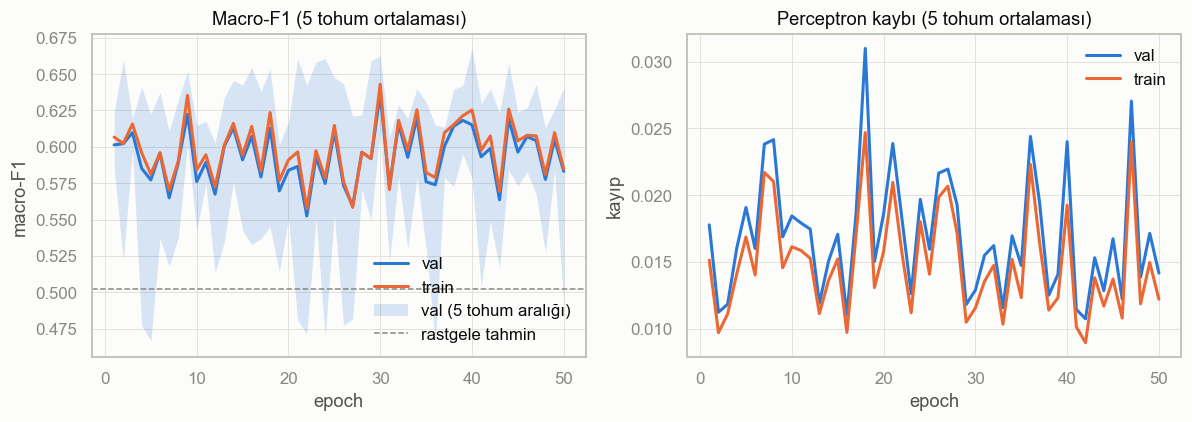

In [12]:
fig, (ax_f1, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))
epochs = np.arange(1, N_EPOCHS + 1)
colors = {"val": SERIES[0], "train": SERIES[1]}

for split in ("val", "train"):
    part = summary.loc[split]
    ax_f1.plot(epochs, part[("macro_f1", "mean")], color=colors[split], label=split)
    ax_loss.plot(epochs, part[("loss", "mean")], color=colors[split], label=split)
val_part = summary.loc["val"]
ax_f1.fill_between(
    epochs, val_part[("macro_f1", "min")], val_part[("macro_f1", "max")],
    color=colors["val"], alpha=0.18, linewidth=0, label="val (5 tohum aralığı)",
)
dummy_f1 = results["dummy_stratified"]["macro_f1"]
ax_f1.axhline(dummy_f1, color=INK_MUTED, linestyle="--", linewidth=1, label="rastgele tahmin")

ax_f1.set(title="Macro-F1 (5 tohum ortalaması)", xlabel="epoch", ylabel="macro-F1")
ax_loss.set(title="Perceptron kaybı (5 tohum ortalaması)", xlabel="epoch", ylabel="kayıp")
ax_f1.legend(loc="lower right")
ax_loss.legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "extra_perceptron_curve")
plt.show()

**Yorum**

- **Öğrenme ilk turda bitiyor.** Val macro-F1 1. turda 0,601, 50. turda 0,583. Sonraki turlar
  ortalamayı yükseltmiyor, yalnızca 0,55–0,64 arasında zikzak çizdiriyor. Daha uzun eğitmek
  işe yaramıyor; varsayılan erken durma (birkaç turda kesmek) bu yüzden zararsız.
- **Ezber (overfitting) yok:** train ve val eğrileri neredeyse üst üste. Sorun modelin
  gördüğü veriyi ezberlemesi değil, doğrusal bir sınırın bu problemi ayıramaması
  (**underfitting**).
- **Yakınsama yok:** kayıp düzenli azalmıyor, sıçrıyor. Veri doğrusal ayrılamadığı için her tur
  yanlış kalan satırlar ağırlıkları farklı yönlere itiyor.
- **Durma noktası şansa bağlı:** aynı turda 5 tohum arasındaki fark 0,47–0,67'ye kadar açılıyor.
  Bölüm 3'te seçimi tek tohumla değil 5 tohum ortalamasıyla yapmamızın sebebi bu.
- Bölüm 3'teki tarama (`fit`) ile buradaki eğri (`partial_fit`) aynı ayarlarla farklı
  karıştırma sıraları kullandığı için birebir aynı sayıları vermez (0,636 ve ≈0,59); ikisi de
  aynı gürültü bandının içinde.
- **Sonuç:** Perceptron'un tavanı ≈0,60–0,64 macro-F1. Bu tavanı aşmak için doğrusal olmayan
  bir model gerekiyor: LightGBM.

## 5. LightGBM: varsayılan model ve CV

LightGBM ağaçları **sırayla** ekler: her yeni ağaç, önceki ağaçların toplam tahmininin hatasını
(log-loss'un gradyanını) düzeltecek şekilde kurulur, katkısı `learning_rate` ile küçültülür.
Tek bir doğrusal sınır yerine çok sayıda eşik bölmesinin toplamı olduğu için Perceptron'un
yakalayamadığı doğrusal olmayan ilişkileri (ör. "PAY_0 ≥ 2 ise risk sıçrar") öğrenebilir.

- **Ön işleme yok:** `make_preprocessor("tree")` 23 ham kolonu olduğu gibi geçirir (`to_xy` zaten
  bu kolonları verir). Ağaçlar eşik bölmesi yaptığı için ölçekleme gerekmez.
- **5-fold StratifiedKFold:** train 5 parçaya bölünür, her parça bir kez ölçüm, kalan 4'ü eğitim
  için kullanılır. Skor 5 parçanın ortalaması ± std. Val seti bu bölümde **kullanılmaz**; model
  seçimine karışmadığı için bağımsız kalır.
- **Early stopping:** `n_estimators=2000` yalnızca üst sınır. Her ağaçtan sonra fold'un ölçüm
  parçasında PR-AUC ölçülür; 100 ağaç boyunca iyileşme olmazsa eğitim kesilir ve en iyi turdaki
  ağaç sayısı kullanılır. Basitleştirme: aynı parça hem durdurma hem skor için kullanıldığı için
  CV skoru hafif iyimserdir; tüm konfigürasyonlar aynı şekilde ölçüldüğünden karşılaştırma adildir.
- **Kategorik kolonlar ve bir tuzak:** LightGBM kategorik kolonları sıraya bakmadan gruplara
  ayırabilir (ör. EDUCATION {1, 3} ve {2, 4, 5}). Ancak kategorik kolondaki **negatif değerleri
  eksik veri sayar**; PAY_x'teki −2 ve −1 kodları en bilgilendirici kodlar. Bu yüzden kolonlar
  `CAT_LEVELS`'taki sabit listeyle pandas `category` tipine çevrilir: LightGBM ham değeri değil
  0'dan başlayan kategori kodunu görür ve aynı kod train/val/test'te aynı anlama gelir.
  `category` tipindeki kolonlar `categorical_feature="auto"` ile otomatik tanınır.

In [13]:
LGBM_FIXED = {
    "n_estimators": 2000,  # upper bound only, early stopping picks the real count
    "metric": "average_precision",  # the only metric, so early stopping watches PR-AUC
    "random_state": SEED,
    "verbose": -1,
}
N_FOLDS = 5
EARLY_STOP = 100


def to_lgbm(X: pd.DataFrame, cat_cols: list[str]) -> pd.DataFrame:
    """Copy of X with cat_cols as fixed-level pandas categories."""
    X = X.copy()
    for col in cat_cols:
        # LightGBM reads negative category values as missing (PAY_x has -2 and -1),
        # so it gets the 0..k codes of a fixed level list instead of the raw values
        X[col] = pd.Categorical(X[col], categories=CAT_LEVELS[col])
    return X


def cv_lgbm(
    params: dict, X: pd.DataFrame, y: pd.Series, trial: optuna.Trial | None = None
) -> dict:
    """5-fold stratified CV PR-AUC with early stopping on each held-out fold.

    With a trial, the running score sum is reported after each fold so Optuna can prune.
    """
    folds = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    scores, best_iters = [], []
    for fold, (fit_idx, stop_idx) in enumerate(folds.split(X, y)):
        X_stop, y_stop = X.iloc[stop_idx], y.iloc[stop_idx]
        model = LGBMClassifier(**(LGBM_FIXED | params)).fit(
            X.iloc[fit_idx], y.iloc[fit_idx], eval_X=X_stop, eval_y=y_stop,
            callbacks=[early_stopping(EARLY_STOP, verbose=False)],
        )
        scores.append(average_precision_score(y_stop, model.predict_proba(X_stop)[:, 1]))
        best_iters.append(model.best_iteration_)
        if trial is not None:
            # MedianPruner compares this trial's best value over all steps with the others'
            # value at the current step. A running mean falls as harder folds arrive, so its
            # best stays at fold 0 and nothing is ever pruned. The sum only grows, so its best
            # is the current step, and comparing sums at one step equals comparing means.
            trial.report(float(np.sum(scores)), fold)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return {
        "pr_auc": float(np.mean(scores)),
        "pr_auc_std": float(np.std(scores)),
        "best_iter": int(np.mean(best_iters)),
    }

### 5.1 PAY_x kategorik mi, sayısal mı?

SEX, EDUCATION ve MARRIAGE gerçekten **nominal** (sıra yok). PAY_x ise **sıralı**: −2 → 8, gecikme
ayı arttıkça risk artar. Hangisinin daha iyi olduğunu tahmin etmek yerine varsayılan parametrelerle
CV'de ölçüyoruz.

In [14]:
CAT_SETUPS = {
    "hepsi sayısal": [],
    "nominal kategorik": NOMINAL_COLS,
    "nominal + PAY_x kategorik": CAT_COLS,
}
cat_rows = []
start = time.perf_counter()
for name, cat_cols in CAT_SETUPS.items():
    cat_rows.append({"setup": name} | cv_lgbm({}, to_lgbm(X_train, cat_cols), y_train))
print(f"{len(CAT_SETUPS)} × {N_FOLDS}-fold CV, {time.perf_counter() - start:.1f} sn")
pd.DataFrame(cat_rows).set_index("setup")

3 × 5-fold CV, 23.1 sn


,pr_auc,pr_auc_std,best_iter
setup,,,
hepsi sayısal,0.5630,0.0114,39
nominal kategorik,0.5629,0.0114,59
nominal + PAY_x kategorik,0.5605,0.0110,32


**Yorum**

- Üç ayar birbirinden ayırt edilemiyor: farklar (≤0,0025) fold'lar arası std'nin (≈0,011)
  çok altında.
- Fark çıkmadığı için anlamı doğru olan seçiliyor: **nominal kolonlar kategorik, PAY_x
  sayısal.** PAY_x'i sayısal bırakmak sırayı korur; ağaç "PAY_0 ≥ 2" gibi tek bir eşikle
  bölebilir. Kategorik yapınca bu sırayı her bölmede veriden yeniden öğrenmesi gerekir.
- Varsayılan `learning_rate=0.1` ile early stopping 30–60 ağaçta duruyor; 2000 sınırına hiç
  yaklaşılmıyor. Daha küçük learning rate'le daha çok ağaç gerekir; bu dengeyi Optuna arayacak.

In [15]:
LGBM_CAT_COLS = NOMINAL_COLS
L_train = to_lgbm(X_train, LGBM_CAT_COLS)
L_val = to_lgbm(X_val, LGBM_CAT_COLS)


def lgbm_on_val(params: dict, n_estimators: int) -> dict:
    """Refit on the full train with the CV tree count, score on val at its own threshold."""
    model = LGBMClassifier(**(LGBM_FIXED | params | {"n_estimators": n_estimators}))
    y_score = model.fit(L_train, y_train).predict_proba(L_val)[:, 1]
    threshold = pick_threshold(y_val, y_score)
    return evaluate(y_val, y_score, (y_score >= threshold).astype(int))


cv_default = cv_lgbm({}, L_train, y_train)
print(f"Varsayılan LGBM, CV PR-AUC = {cv_default['pr_auc']:.4f} ± {cv_default['pr_auc_std']:.4f}, "
      f"{cv_default['best_iter']} ağaç")
results["lgbm (varsayılan)"] = lgbm_on_val({}, cv_default["best_iter"])
pd.DataFrame(results).T.astype(float)

Varsayılan LGBM, CV PR-AUC = 0.5629 ± 0.0114, 59 ağaç


,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy
dummy_most_frequent,0.4378,0.6820,0.5000,0.2211,0.7789
dummy_stratified,0.5019,0.6573,0.5019,0.2218,0.6578
perceptron (5 tohum ort.),0.6356,0.7560,0.6764,0.4069,0.7635
lgbm (varsayılan),0.7071,0.8033,0.7779,0.5534,0.8087


**Yorum**

- **Varsayılan LightGBM, Perceptron'un tavanını açık farkla aşıyor:** val macro-F1 0,707
  (Perceptron 0,636), ROC-AUC 0,778 (0,676), PR-AUC 0,553 (0,407). Aradaki fark parametre
  ayarından değil model ailesinden geliyor: Bölüm 4'te gördüğümüz underfitting'in çaresi
  doğrusal olmayan bölmeler.
- Sayılar Öğrenci 1'in sabit parametreli LightGBM'i ile (0,707 / 0,777, `reports/tstr_trtr.csv`)
  örtüşüyor; farklı ağaç sayısı ve learning rate ile aynı sonuca varılması iki hattın da
  tutarlı olduğunu gösteriyor.
- CV PR-AUC (0,563) ile val PR-AUC (0,553) yakın; CV skoru val'in iyi bir tahmincisi. Optuna
  bu yüzden val'e hiç dokunmadan, yalnızca CV skoruyla arama yapabilir.

## 6. LightGBM: Optuna araması

- **Amaç:** `cv_lgbm`'in ortalama PR-AUC'si maksimize edilir. PR-AUC eşikten bağımsızdır (eşik
  sonra val'de seçilir) ve dengesiz veride ROC-AUC'den dürüsttür: ROC'un yanlış-pozitif oranı
  büyük negatif sınıfın içinde erir, PR-AUC ise doğrudan pozitif tahminlerin isabetine bakar.
- **TPE (Tree-structured Parzen Estimator):** Biten denemeleri "iyi" ve "kötü" diye ikiye ayırır,
  her grup için parametre yoğunluğu $l(x)$ ve $g(x)$ tahmin eder ve $l(x)/g(x)$ oranı yüksek
  bölgeden yeni aday önerir. İlk 10 deneme rastgeledir; sonrası geçmişten öğrenir. 9 parametrelik
  uzayda grid search mümkün değil, TPE aramayı umut veren bölgeye yoğunlaştırır.
- **MedianPruner:** `cv_lgbm` her fold'dan sonra o ana kadarki skorların toplamını raporlar. Bir
  deneme aynı adımda önceki denemelerin medyanının altındaysa kesilir. Karşılaştırma adildir çünkü tüm
  denemeler aynı fold'ları aynı sırayla görür. İlk 5 deneme ve ilk fold kesilmez.
  **Tuzak:** ilk sürümde koşu *ortalaması* raporlanıyordu ve 50 denemede hiçbiri kesilmedi.
  Pruner denemenin tüm adımlardaki *en iyi* değerini kullanır; ortalama fold'lar ilerledikçe
  düştüğü için (0,58 → 0,56) en iyi değer hep fold 0'da kalıyordu. Toplam ise hep artar.
- **Kayıt:** Study `models/optuna_lgbm.db` (sqlite) dosyasına yazılır; kesilirse kaldığı yerden
  devam eder ve notebook yeniden çalıştırıldığında biten denemeler tekrarlanmaz. (Sampler'ın iç
  durumu dosyaya yazılmaz; yarıda kesilip devam eden bir arama, tek seferde biten aramayla
  birebir aynı denemeleri üretmeyebilir.)
- **`max_depth` koşullu:** önce "derinlik sınırlansın mı?" sorulur, evet ise 3–12 aranır.
  `subsample` her turda uygulanması için `subsample_freq=1` ile verilir.

In [16]:
N_TRIALS_PROBE, N_TRIALS = 10, 50
OPTUNA_DB = MODELS_DIR / "optuna_lgbm.db"


def suggest_lgbm(trial: optuna.Trial) -> dict:
    """Search space from the team plan (section 8, step 3) as LightGBM parameters."""
    limit_depth = trial.suggest_categorical("limit_depth", [False, True])
    return {
        "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12) if limit_depth else -1,
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,  # without it LightGBM ignores subsample
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 4.0),
    }


def objective(trial: optuna.Trial) -> float:
    cv = cv_lgbm(suggest_lgbm(trial), L_train, y_train, trial)
    trial.set_user_attr("pr_auc_std", cv["pr_auc_std"])
    trial.set_user_attr("best_iter", cv["best_iter"])
    return cv["pr_auc"]


def run_until(study: optuna.Study, n_total: int) -> None:
    """Top the study up to n_total finished trials; already stored ones are not repeated."""
    n_done = sum(t.state.is_finished() for t in study.trials)
    start = time.perf_counter()
    study.optimize(objective, n_trials=max(0, n_total - n_done))
    n_new = sum(t.state.is_finished() for t in study.trials) - n_done
    if n_new:
        elapsed = time.perf_counter() - start
        print(f"{n_new} yeni deneme, {elapsed:.0f} sn ({elapsed / n_new:.1f} sn/deneme)")
    else:
        print(f"{n_total} deneme zaten kayıtlı, arama atlandı")


optuna.logging.set_verbosity(optuna.logging.WARNING)
MODELS_DIR.mkdir(exist_ok=True)
study = optuna.create_study(
    study_name=f"lgbm_{VARIANT}",
    storage=f"sqlite:///{OPTUNA_DB.as_posix()}",
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    load_if_exists=True,
)
run_until(study, N_TRIALS_PROBE)  # timing probe before the full search

10 deneme zaten kayıtlı, arama atlandı


In [17]:
run_until(study, N_TRIALS)

trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs"))
trials.columns = [col.removeprefix("params_").removeprefix("user_attrs_") for col in trials.columns]
print(trials.state.value_counts().to_dict())
# A pruned trial's value is its last reported fold-score sum, not a mean, so rank finished ones only
complete = trials[trials.state == "COMPLETE"].drop(columns="state")
complete.sort_values("value", ascending=False).head(5)

50 deneme zaten kayıtlı, arama atlandı
{'PRUNED': 30, 'COMPLETE': 20}


,number,value,colsample_bytree,learning_rate,limit_depth,max_depth,min_child_samples,num_leaves,reg_alpha,reg_lambda,scale_pos_weight,subsample,best_iter,pr_auc_std
32,32,0.5667,0.7267,0.0165,True,9.0000,14,66,0.7595,0.0727,1.0058,0.5843,176.0000,0.0125
48,48,0.5663,0.7477,0.0160,True,7.0000,30,60,0.7254,2.2179,1.0203,0.6381,221.0000,0.0116
44,44,0.5661,0.8155,0.0108,True,7.0000,18,51,0.9690,0.2296,1.4078,0.6683,255.0000,0.0122
37,37,0.5658,0.7418,0.0152,True,10.0000,24,69,0.2991,1.5312,1.2924,0.6382,195.0000,0.0121
43,43,0.5657,0.7863,0.0207,True,7.0000,11,61,0.3477,0.2871,1.2073,0.6925,157.0000,0.0129


In [18]:
best_trial = study.best_trial
# FixedTrial replays the stored answers through the same function, so the conditional
# max_depth and the fixed subsample_freq are rebuilt exactly as during the search
LGBM_PARAMS = suggest_lgbm(optuna.trial.FixedTrial(best_trial.params))
LGBM_N_ESTIMATORS = best_trial.user_attrs["best_iter"]
print(f"En iyi deneme #{best_trial.number}: CV PR-AUC = {best_trial.value:.4f} "
      f"± {best_trial.user_attrs['pr_auc_std']:.4f}, {LGBM_N_ESTIMATORS} ağaç")
print(f"Varsayılan:           CV PR-AUC = {cv_default['pr_auc']:.4f} "
      f"± {cv_default['pr_auc_std']:.4f}")
display(pd.Series(LGBM_PARAMS, name="değer").to_frame())

results["lgbm (optuna)"] = lgbm_on_val(LGBM_PARAMS, LGBM_N_ESTIMATORS)
pd.DataFrame(results).T.astype(float)

En iyi deneme #32: CV PR-AUC = 0.5667 ± 0.0125, 176 ağaç
Varsayılan:           CV PR-AUC = 0.5629 ± 0.0114


,değer
num_leaves,66.0000
learning_rate,0.0165
max_depth,9.0000
min_child_samples,14.0000
subsample,0.5843
subsample_freq,1.0000
colsample_bytree,0.7267
reg_alpha,0.7595
reg_lambda,0.0727
scale_pos_weight,1.0058


,macro_f1,weighted_f1,roc_auc,pr_auc,accuracy
dummy_most_frequent,0.4378,0.6820,0.5000,0.2211,0.7789
dummy_stratified,0.5019,0.6573,0.5019,0.2218,0.6578
perceptron (5 tohum ort.),0.6356,0.7560,0.6764,0.4069,0.7635
lgbm (varsayılan),0.7071,0.8033,0.7779,0.5534,0.8087
lgbm (optuna),0.7113,0.8045,0.7766,0.5517,0.8080


**Yorum**

- **Pruner işe yarıyor:** 50 denemenin 30'u ilk fold'larda kesildi; deneme başına süre ilk
  (ortalama raporlanan, hiç kesmeyen) sürüme göre ≈13 sn'den ≈9 sn'ye indi.
- **Optuna'nın kazancı küçük:** CV PR-AUC 0,563 → 0,567, yani fold'lar arası std'nin (≈0,012)
  altında. Val'de macro-F1 0,707 → 0,711, PR-AUC ve ROC-AUC ise aynı (0,552 / 0,777).
  Varsayılan LightGBM bu veride zaten tavana yakın; kalan hata parametreden değil, 23 özelliğin
  taşıdığı bilgiden kaynaklanıyor.
- **Bulunan bölge:** düşük `learning_rate` (≈0,02) + daha çok ağaç (≈180), satır ve kolon
  örnekleme (`subsample` ≈0,6, `colsample_bytree` ≈0,7). Bunlar düzenlileştirme etkisi yapar:
  her ağaç verinin bir kısmını görür, tek tek ağaçların ezberi ortalamada söner.
- **`scale_pos_weight` ≈ 1:** en iyi denemelerde sınıf ağırlığı neredeyse hiç kullanılmıyor.
  Perceptron'daki `class_weight` bulgusuyla aynı: eşik val'de seçildiği için dengesizlik eşikle
  telafi ediliyor.
- Final LightGBM bu parametrelerle kurulacak (`LGBM_PARAMS`, `LGBM_N_ESTIMATORS`).

## 7. Optuna grafikleri ve özellik önemi

- **Optimization history:** her tamamlanan denemenin CV PR-AUC'si (nokta) ve o ana kadarki en
  iyi skor (basamak çizgisi). Kesilen denemelerin skoru bir toplam olduğu için çizilmez.
- **Parametre önemi (fANOVA):** tamamlanan denemelerden "parametreler → skor" ilişkisine bir
  random forest uydurulur, skordaki varyansın hangi parametreden geldiği ayrıştırılır.
  Basitleştirme: yalnızca 20 tamamlanmış deneme var ve TPE bunları iyi bölgeye yığdığı için
  sıralama kabaca okunmalı. Her denemede bulunmayan koşullu `max_depth` hesaba girmez.
- **Özellik önemi:** `split` bir özelliğin kaç bölmede kullanıldığını, `gain` bu bölmelerin
  kayıpta sağladığı toplam düşüşü sayar. Çok farklı değeri olan sürekli kolonlar (ör. BILL_AMT)
  eşik için çok fırsat sunduğundan `split`'te şişer; modele asıl katkıyı `gain` gösterir.
  Önem, Optuna parametreleriyle tüm train'e fit edilen modelden alınır (23 ham özellik,
  Öğrenci 3'ün Grafik 4'ünde TabNet ile aynı eksende).

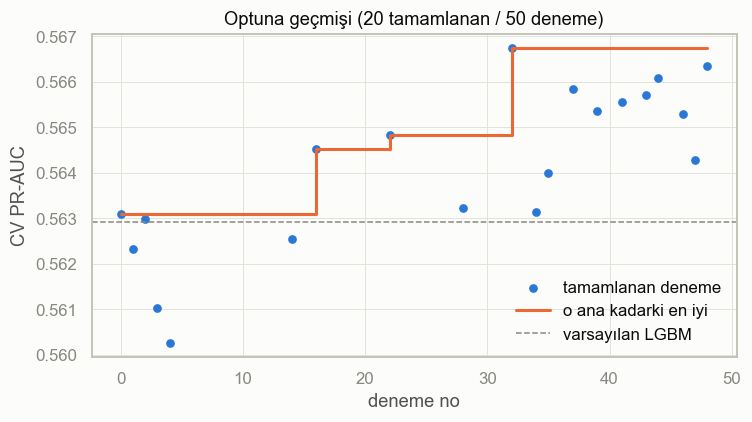

In [19]:
complete = complete.sort_values("number")
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(complete.number, complete.value, color=SERIES[0], s=22, label="tamamlanan deneme")
ax.step(complete.number, complete.value.cummax(), where="post", color=SERIES[1],
        label="o ana kadarki en iyi")
ax.axhline(cv_default["pr_auc"], color=INK_MUTED, linestyle="--", linewidth=1,
           label="varsayılan LGBM")
ax.set(title=f"Optuna geçmişi ({len(complete)} tamamlanan / {len(trials)} deneme)",
       xlabel="deneme no", ylabel="CV PR-AUC")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "extra_optuna_history")
plt.show()

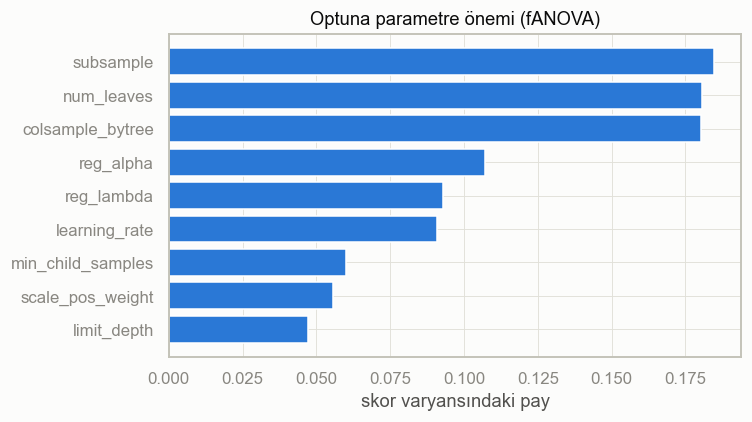

In [20]:
param_importance = pd.Series(
    optuna.importance.get_param_importances(
        study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)
    )
).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(param_importance.index, param_importance.values, color=SERIES[0])
ax.set(title="Optuna parametre önemi (fANOVA)", xlabel="skor varyansındaki pay")
fig.tight_layout()
save_fig(fig, "extra_optuna_importance")
plt.show()

In [21]:
tuned_lgbm = LGBMClassifier(**(LGBM_FIXED | LGBM_PARAMS | {"n_estimators": LGBM_N_ESTIMATORS}))
tuned_lgbm.fit(L_train, y_train)
importance = pd.DataFrame({
    "feature": tuned_lgbm.booster_.feature_name(),
    "gain": tuned_lgbm.booster_.feature_importance(importance_type="gain"),
    "split": tuned_lgbm.booster_.feature_importance(importance_type="split"),
}).sort_values("gain", ascending=False, ignore_index=True)
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
importance.to_csv(IMPORTANCE_DIR / "lgbm_importance.csv", index=False)

# Shares make the two scales comparable; the rank gap shows where split and gain disagree
shares = importance.assign(
    gain_share=importance.gain / importance.gain.sum(),
    split_share=importance.split / importance.split.sum(),
    split_rank=importance.split.rank(ascending=False).astype(int),
)
shares.head(10)[["feature", "gain_share", "split_share", "split_rank"]]

,feature,gain_share,split_share,split_rank
0,PAY_0,0.3292,0.0263,15
1,PAY_2,0.0883,0.0150,18
2,BILL_AMT1,0.0520,0.0839,1
3,LIMIT_BAL,0.0487,0.0715,2
4,PAY_AMT2,0.0453,0.0710,3
5,PAY_AMT1,0.0430,0.0660,4
6,PAY_AMT3,0.0406,0.0659,5
7,PAY_AMT4,0.0368,0.0626,8
8,PAY_AMT6,0.0358,0.0656,6
9,BILL_AMT2,0.0319,0.0608,10


**Yorum**

- **Geçmiş grafiği yakından okunmalı:** y ekseni yalnızca 0,560–0,567 aralığını gösteriyor. En
  iyi skorun varsayılana göre artışı 0,004; fold std'si (≈0,012) bunun üç katı. TPE 30.
  denemeden sonra noktaları iyi bölgeye yığıyor (0,563–0,567), yani arama yakınsamış.
- **Parametre önemi düz:** baskın bir parametre yok; ilk üçü (`subsample`, `num_leaves`,
  `colsample_bytree`) ≈%18'er. Skor yüzeyi bu aralıkta düz olduğu için hangi parametreyi
  değiştirsek de skor çok az oynuyor; Optuna'nın küçük kazancıyla tutarlı.
- **Özellik önemi:** `PAY_0` (son ayın ödeme durumu) gain'in **%33'ünü** tek başına alıyor,
  `PAY_2` %9 ile ikinci. Ama `split` sıralamasında 15. ve 18.: az sayıda bölmede kullanılıyor,
  her bölme çok kazandırıyor. Tersine `BILL_AMT1` ve `LIMIT_BAL` split'te 1. ve 2. ama gain payları
  ≈%5: sürekli kolonlar eşik denemek için çok fırsat sunduğundan sık bölünüyor, her bölme az
  kazandırıyor. Modelin kararını açıklamak için **gain** kullanılmalı.
- Bu tablo Perceptron'un neden zorlandığını da açıklıyor: en güçlü sinyal sıralı bir gecikme
  kodunda ve etkisi eşik biçiminde ("ödemeyi geciktirdi mi?"), doğrusal bir ağırlıkla değil.